In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import math
from scipy.integrate import solve_ivp, cumulative_trapezoid, quad, solve_bvp
from scipy.interpolate import CubicSpline
from numba import jit, njit, prange

In [2]:
# Set som plotting standards:
font = {'family' : 'serif',
        'weight' : 'normal',
        'size'   : 18}
mpl.rc('font', **font)

axes = {'facecolor': 'ghostwhite'}
mpl.rc('axes', **axes)

# Set custom color cycle
custom_colors= ['dodgerblue', 'red', 'limegreen', 'orange', 'orchid', 'black', 'slategrey', 
                'navy', 'magenta', 'forestgreen', 'lightblue', 'maroon', 'gold', 'lightcoral', 
                'mediumseagreen', 'darkorange', 'darkviolet', 'dimgray', 'darkblue', 'darkred',]
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=custom_colors)

# Set inside tickmarks
mpl.rcParams['xtick.direction'] = 'in'
mpl.rcParams['ytick.direction'] = 'in'
mpl.rcParams['xtick.minor.visible'] = True
mpl.rcParams['ytick.minor.visible'] = True

In [3]:
from Functions import compute_for_sigmoidal

# Functions

In [4]:
def compute_for_two_state(
    r_target,
    rf,
    rn,
    A,
    b,
    D0,
    Dn,
    lambda0=0.01,
    gamma=0.01,
    ndim=3,
    N=4000,
    tol=1e-4,
    max_nodes=20000,
):
    """
    Computes both T_A(r) and T_I(r) for the two-state model.

    Active state:
        -1 = LT_A - gamma * (T_A - T_I)
        T_A(r_target) = 0
        T_A'(rn) = 0

    Inactive state:
        -1 = LT_I - lambda(r) * (T_I - T_A)
        T_I'(r_target) = 0
        T_I'(rn) = 0

    where L is the generator of the diffusion process:
        Lf = D(r) f'' + mu(r) f'

    Parameters
    ----------
    r_target : float
        Target radius.
    rf : float
        Droplet radius (where the sigmoidal functions are centered).
    rn : float
        Outer reflecting boundary radius.
    A : float
        Amplitude of the sigmoidal function for the potential U(r).
    b : float
        Steepness of the sigmoidal function for the potential U(r).
    D0 : float
        Diffusion coefficient inside the droplet (r < rf).
    Dn : float
        Diffusion coefficient outside the droplet (r > rf).
    lambda0 : float, optional
        Maximum activation rate (default 0.01).
    gamma : float, optional
        Deactivation rate (default 0.01).
    ndim : int, optional
        Spatial dimension (default 3).
    N : int, optional
        Number of spatial grid points.
    tol : float, optional
        Tolerance for the solution (default 1e-4).
    max_nodes : int, optional
        Maximum number of nodes for the solver (default 20000).


    Returns
    -------
    TA_func : callable
        Interpolating function for T_A(r).
    TI_func : callable
        Interpolating function for T_I(r).
    out : dict
        Diagnostics and raw arrays.
    """

    # ------------------------------------------------------------
    # Define U(r), D(r), and related functions
    # ------------------------------------------------------------
    def exp_term(rr):
        return np.exp(-b * (rr - rf))
    
    def D_func(rr):
        e = exp_term(rr)
        return D0 + (Dn - D0) / (1 + e)
    
    def dD_func(rr):
        e = exp_term(rr)
        return (Dn - D0) * b * e / (1 + e)**2

    def dU_func(rr):
        e = exp_term(rr)
        return A * b * e / (1 + e)**2

    def drift(rr):
        return (ndim - 1) * D_func(rr) / rr + dD_func(rr) - D_func(rr) * dU_func(rr)

    def activation(rr):
        e = exp_term(rr)
        return lambda0 * e / (1 + e)

    # ============================================================
    # BVP system
    # ============================================================
    # Unknown vector:
    # y[0] = T_A
    # y[1] = T_A'
    # y[2] = T_I
    # y[3] = T_I'

    def ode_system(r, y):
        TA, dTA, TI, dTI = y

        D = D_func(r)
        mu = drift(r)
        lam = activation(r)

        # From:
        # -1 = mu dTA + D d2TA - gamma (TA - TI)
        # -1 = mu dTI + D d2TI - lambda(r) (TI - TA)
        #
        # Therefore:
        # d2TA = [ -1 - mu dTA + gamma (TA - TI) ] / D
        # d2TI = [ -1 - mu dTI + lambda(r) (TI - TA) ] / D

        ddTA = (-1.0 - mu * dTA + gamma * (TA - TI)) / D
        ddTI = (-1.0 - mu * dTI + lam   * (TI - TA)) / D

        return np.vstack((dTA, ddTA, dTI, ddTI))

    def bc(ya, yb):
        """
        Boundary conditions:
        T_A(r_target)   = 0
        T_A'(rn)  = 0
        T_I'(r_target)  = 0
        T_I'(rn)  = 0
        """
        return np.array([
            ya[0],      # T_A(r_target) = 0
            yb[1],      # T_A'(rn) = 0
            ya[3],      # T_I'(r_target) = 0
            yb[3],      # T_I'(rn) = 0
        ])
    
    # ============================================================
    # Initial mesh and guess
    # ============================================================

    r_mesh = np.linspace(r_target, rn, N)

    # A simple initial guess:
    L = rn - r_target
    x = (r_mesh - r_target) / L

    TA_guess = L**2 * (2*x - x**2)   # TA(r_target)=0, TA'(rn)=0
    dTA_guess = 2*L*(1 - x)

    TI_guess = np.full_like(r_mesh, L**2)   # constant => derivative zero at both ends
    dTI_guess = np.zeros_like(r_mesh)

    y_guess = np.vstack((TA_guess, dTA_guess, TI_guess, dTI_guess))

    # ============================================================
    # Solve the boundary value problem
    # ============================================================

    sol = solve_bvp(ode_system, bc, r_mesh, y_guess, tol=tol, max_nodes=max_nodes)

    if not sol.success:
        raise RuntimeError(f"BVP solver failed: {sol.message}")
   
    # ============================================================
    # Evaluate and interpolate solutions
    # ============================================================
        
    r_eval = np.linspace(r_target, rn, 1000)
    TA_sol = sol.sol(r_eval)[0]
    TI_sol = sol.sol(r_eval)[2]

    TA_spline = CubicSpline(r_eval, TA_sol, bc_type="natural", extrapolate=False)
    TI_spline = CubicSpline(r_eval, TI_sol, bc_type="natural", extrapolate=False)
    
    def TA_func(r):
        r = np.asarray(r)
        if np.any((r < r_target) | (r > rn)):
            raise ValueError("r must lie within [r_target, rn].")
        return TA_spline(r)

    def TI_func(r):
        r = np.asarray(r)
        if np.any((r < r_target) | (r > rn)):
            raise ValueError("r must lie within [r_target, rn].")
        return TI_spline(r)

    out = {
        "r_grid": r_eval,
        "TA_values": TA_sol,
        "TI_values": TI_sol,
        "TA_rn": float(TA_spline(rn)),
        "TI_rn": float(TI_spline(rn)),
        "drift": drift,
        "lambda_values": activation(r_eval),
    }

    return TA_func, TI_func, out

In [5]:
# ──────────────────────────────────────────────────────────────────────────────
# Numba-compiled helpers for simulation (no Python objects, no closures — plain scalars only)
# ──────────────────────────────────────────────────────────────────────────────

@njit(cache=True)
def _exp_term(r, b, rf):
    return np.exp(-b * (r - rf))

@njit(cache=True)
def _D_func(r, b, rf, D0, Dn):
    e = _exp_term(r, b, rf)
    return D0 + (Dn - D0) / (1.0 + e)

@njit(cache=True)
def _dD_func(r, b, rf, D0, Dn):
    e = _exp_term(r, b, rf)
    return (Dn - D0) * b * e / (1.0 + e) ** 2

@njit(cache=True)
def _dU_func(r, b, rf, A):
    e = _exp_term(r, b, rf)
    return A * b * e / (1.0 + e) ** 2

@njit(cache=True)
def _mu_func(r, b, rf, A, D0, Dn, ndim):
    D  = _D_func(r, b, rf, D0, Dn)
    dD = _dD_func(r, b, rf, D0, Dn)
    dU = _dU_func(r, b, rf, A)
    return (ndim - 1) * D / r + dD - D * dU

@njit(cache=True)
def _lambda_func(r, b, rf, lambda0):
    e = _exp_term(r, b, rf)
    return lambda0 * e / (1.0 + e)

@njit(cache=True)
def _t_step(r, dt_max, alpha, b, rf, A):
    e = _exp_term(r, b, rf)
    return dt_max / (1.0 + alpha * np.abs(A * b * e / (1.0 + e) ** 2))


@njit(cache=True, parallel=True)
def _run_trajectories(
    r0, state0, r_target, rf, rn,
    A, b, D0, Dn, lambda0, gamma,
    dt_max, alpha, 
    ndim, n_trajectories, max_steps,
):
    """
    Core simulation loop — fully compiled and parallelised across trajectories.
    Includes adaptive time stepping based on local potential gradients.

    Returns
    -------
    fpt_samples : float64 array, length n_trajectories
        NaN for trajectories that did not complete.
    """
    #sqrt_dt = np.sqrt(dt)
    fpt_samples = np.full(n_trajectories, np.nan)

    for traj in prange(n_trajectories):          # parallel across trajectories
        r     = r0
        state = state0                           # active (1) or inactive (0)
        t     = 0.0

        for _ in range(max_steps):

            # Compute adaptive time step based on local rates of change
            delta_t = _t_step(r, dt_max=dt_max, alpha=alpha, b=b, rf=rf, A=A)
            sqrt_dt = math.sqrt(delta_t)

            # Compute switching rate at current position and update state
            if state == 0:
                rate = _lambda_func(r, b, rf, lambda0)   # I -> A
            else:
                rate = gamma                              # A -> I

            if rate > 0.0:
                p_switch = 1.0 - math.exp(-rate * delta_t)
                if np.random.rand() < p_switch:
                    state = 1 - state

            D  = _D_func(r, b, rf, D0, Dn)
            mu = _mu_func(r, b, rf, A, D0, Dn, ndim)
            

            # Euler–Maruyama step
            r_new = r + mu * delta_t + np.sqrt(2.0 * D) * sqrt_dt * np.random.standard_normal()

            # Reflect at outer boundary
            if r_new > rn:
                r_new = 2.0 * rn - r_new

            t += delta_t

            if r_new <= r_target:
                if state == 1:
                    # Absorb
                    frac = (r - r_target) / (r - r_new)
                    fpt_samples[traj] = (t - delta_t) + frac * delta_t
                    break
                else:
                    # Reflect inactive particle
                    r_new = 2.0 * r_target - r_new

            r = r_new
        

    return fpt_samples


# ──────────────────────────────────────────────────────────────────────────────
# Public API  (matches the original signature exactly)
# ──────────────────────────────────────────────────────────────────────────────

def simulate_two_state_mfpt(
    r0: float,
    state0: int,
    r_target: float,
    rf: float,
    rn: float,
    A: float,
    b: float,
    D0: float,
    Dn: float,
    lambda0: float = 0.01,
    gamma: float = 0.01,
    dt_max: float = 1e-4,
    alpha: float = 0.05,
    ndim: int = 3,
    n_trajectories: int = 1000,
    max_steps: int = 10_000_000,
    seed: int | None = None,
) -> dict:
    """
    Numba-accelerated two-state MFPT simulator.

    Parameters are identical to the pure-Python version.
    `rng` is replaced by `seed` (int or None) because Numba uses its own
    internal RNG seeded via np.random.seed().
    """
    if seed is not None:
        np.random.seed(seed)

    fpt_samples = _run_trajectories(
        r0, state0, r_target, rf, rn,
        A, b, D0, Dn, lambda0, gamma,
        dt_max, alpha, 
        ndim, n_trajectories, max_steps,
    )

    completed  = fpt_samples[~np.isnan(fpt_samples)]
    n_completed  = len(completed)
    n_truncated  = n_trajectories - n_completed

    return {
        "mean_fpt"   : float(np.mean(completed))                          if n_completed > 0 else np.nan,
        "std_fpt"    : float(np.std(completed))                           if n_completed > 0 else np.nan,
        "stderr_fpt" : float(np.std(completed) / np.sqrt(n_completed))   if n_completed > 1 else np.nan,
        "fpt_samples": completed,
        "n_completed": n_completed,
        "n_truncated": n_truncated,
    }

# Debug with no switching

In [51]:
rf_debug = np.linspace(0.05, 0.15, 10)
mfpt_debug = np.zeros_like(rf_debug)

rt_ = 0.01
rn_ = 0.5
D0_ = 0.05
Dn_ = 1.0
A_ = 10.0
b_ = 500.0
ndim_ = 3

for i, rf in enumerate(rf_debug):
    print(f"Running simulation for rf = {rf:.3f}...")
    result = simulate_two_state_mfpt(
            r0=rn_, state0=1, r_target=rt_, rf=rf, rn=rn_,
            A=A_, b=b_, D0=D0_, Dn=Dn_,
            lambda0=0.0, gamma=0.0,           # no switching
            dt_max=1e-5, alpha=0.1, 
            ndim=3, n_trajectories=2000, max_steps=1000000000
            )
    mfpt_debug[i] = result['mean_fpt']

Running simulation for rf = 0.050...
Running simulation for rf = 0.061...
Running simulation for rf = 0.072...
Running simulation for rf = 0.083...
Running simulation for rf = 0.094...
Running simulation for rf = 0.106...
Running simulation for rf = 0.117...
Running simulation for rf = 0.128...
Running simulation for rf = 0.139...
Running simulation for rf = 0.150...


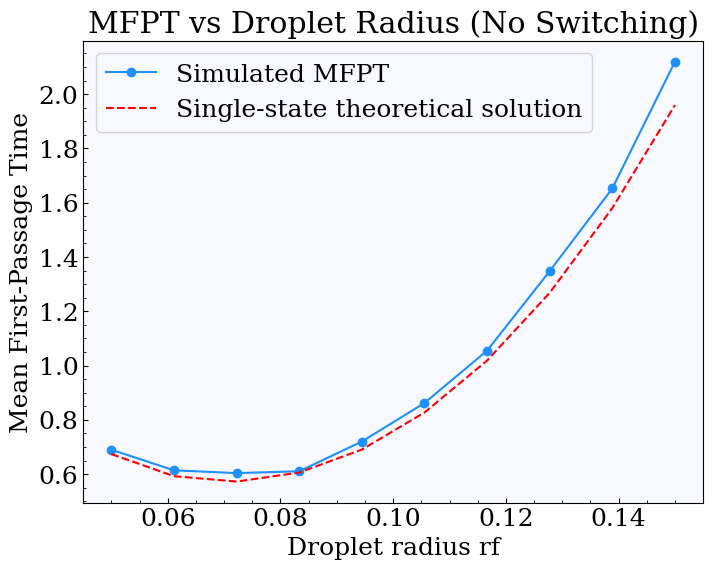

In [52]:
theoretical_mfpt = np.zeros_like(rf_debug)
for i, rf in enumerate(rf_debug):
    func, _ = compute_for_sigmoidal(rt_, rf, rn_, A_, b_, D0_, Dn_, ndim=3, N=400)
    theoretical_mfpt[i] = func(rn_)

plt.figure(figsize=(8,6))
plt.plot(rf_debug, mfpt_debug, 'o-', label='Simulated MFPT')
plt.plot(rf_debug, theoretical_mfpt, 'r--', label='Single-state theoretical solution')
plt.xlabel('Droplet radius rf')
plt.ylabel('Mean First-Passage Time')
plt.title('MFPT vs Droplet Radius (No Switching)')
plt.legend();

In [8]:
# Parameters for computation
r_target = 0.01
rf = 0.1
rn = 0.5
A = 5.0
b = 500.0
D0 = 0.2
Dn = 0.8
D = 0.5

lambda0 = 10.0
gamma = 0.5

# Estimate regime of interest for MFPT
L = rn - r_target
diffusion_time_scale = L**2 / D

print(f"Estimated diffusion time scale: {1/diffusion_time_scale:.2f}")
print(f"Estimated activation time scale: {lambda0:.2f}")
print(f"Estimated deactivation time scale: {gamma:.2f}")

Estimated diffusion time scale: 2.08
Estimated activation time scale: 10.00
Estimated deactivation time scale: 0.50


In [9]:
# Set range of rf values to explore
rf_vals = np.linspace(0.05, 0.15, 25)

T_A = np.zeros(len(rf_vals))
T_I = np.zeros(len(rf_vals))
T_single = np.zeros(len(rf_vals))

for i in range(len(rf_vals)):
    TA_func, TI_func, out = compute_for_two_state(
        r_target=r_target,
        rf=rf_vals[i],
        rn=rn,
        A=A,
        b=b, 
        D0=D,
        Dn=D,
        lambda0=lambda0,
        gamma=gamma,
        ndim=3,
        N=300,
        tol=1e-6,
        max_nodes=20000,
    )
    T_A[i] = out["TA_rn"]
    T_I[i] = out["TI_rn"]
    T_single[i] = compute_for_sigmoidal(r_target, rf_vals[i], rn, A, b, D, D, ndim=3, N=300)[0](rn)

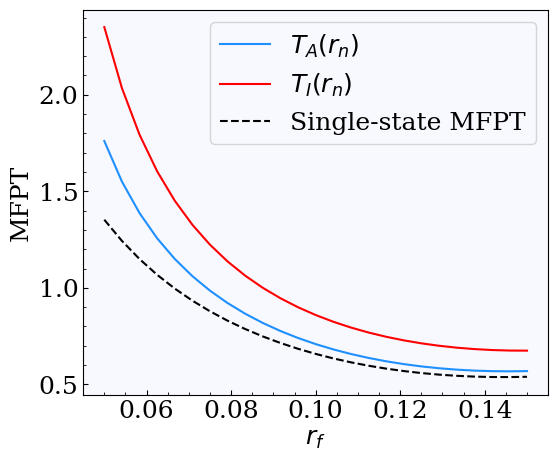

In [10]:
# Plot the simulation results with error bars
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(rf_vals, T_A, label=r'$T_A(r_n)$')
ax.plot(rf_vals, T_I, label=r'$T_I(r_n)$')
ax.plot(rf_vals, T_single, 'k--', label='Single-state MFPT')
ax.set_xlabel(r'$r_f$')
ax.set_ylabel('MFPT')
ax.legend();

In [53]:
# Compare to simulations for every second rf value
rf_truncat = rf_vals[::2]
mfpt_init0 = np.zeros(len(rf_truncat))
std_init0 = np.zeros(len(rf_truncat))

for i, rf_val in enumerate(rf_truncat):
    print(f"Running simulations for rf = {rf_val:.3f}...")
    results = simulate_two_state_mfpt(
    r0=rn, state0=0,
    r_target=r_target, rf=rf_val, rn=rn,
    A=A, b=b, D0=D, Dn=D,
    lambda0=lambda0, gamma=gamma,
    dt_max=1e-5, alpha=0.05,
    ndim=3, n_trajectories=1000)
    mfpt_init0[i] = results['mean_fpt']
    std_init0[i] = results['stderr_fpt']
    

Running simulations for rf = 0.050...
Running simulations for rf = 0.058...
Running simulations for rf = 0.067...
Running simulations for rf = 0.075...
Running simulations for rf = 0.083...
Running simulations for rf = 0.092...
Running simulations for rf = 0.100...
Running simulations for rf = 0.108...
Running simulations for rf = 0.117...
Running simulations for rf = 0.125...
Running simulations for rf = 0.133...
Running simulations for rf = 0.142...
Running simulations for rf = 0.150...


In [55]:
mfpt_init1 = np.zeros(len(rf_truncat))
std_init1 = np.zeros(len(rf_truncat))

for i, rf_val in enumerate(rf_truncat):
    print(f"Running simulations for rf = {rf_val:.3f}...")
    results = simulate_two_state_mfpt(
    r0=rn, state0=1,
    r_target=r_target, rf=rf_val, rn=rn,
    A=A, b=b, D0=D, Dn=D,
    lambda0=lambda0, gamma=gamma,
    dt_max=1e-5, alpha=0.05, 
    ndim=3, n_trajectories=1000)
    mfpt_init1[i] = results['mean_fpt']
    std_init1[i] = results['stderr_fpt']

Running simulations for rf = 0.050...
Running simulations for rf = 0.058...
Running simulations for rf = 0.067...
Running simulations for rf = 0.075...
Running simulations for rf = 0.083...
Running simulations for rf = 0.092...
Running simulations for rf = 0.100...
Running simulations for rf = 0.108...
Running simulations for rf = 0.117...
Running simulations for rf = 0.125...
Running simulations for rf = 0.133...
Running simulations for rf = 0.142...
Running simulations for rf = 0.150...


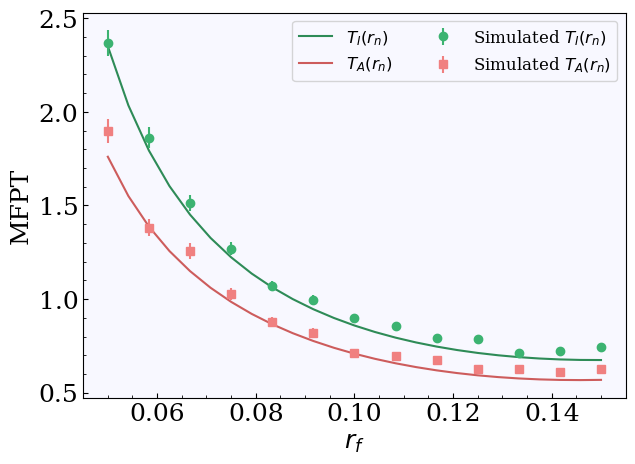

In [56]:
# Plot the simulation results with error bars
fig, ax = plt.subplots(figsize=(7, 5))

# Inactive initial condition (T_I) in green, active initial condition (T_A) in coral
ax.plot(rf_vals, T_I, color='seagreen', label=r'$T_I(r_n)$')
ax.errorbar(rf_truncat, mfpt_init0, yerr=std_init0, fmt='o', color='mediumseagreen', label='Simulated $T_I(r_n)$')

# Active initial condition (T_A) in tomato, with square markers for simulations
ax.plot(rf_vals, T_A, color='indianred', label=r'$T_A(r_n)$')
ax.errorbar(rf_truncat, mfpt_init1, yerr=std_init1, fmt='s', color='lightcoral', label='Simulated $T_A(r_n)$')

ax.set_xlabel(r'$r_f$')
ax.set_ylabel('MFPT')
ax.legend(fontsize=12, ncols=2);

# Investigating full trajectories

# Investigating full trajectories

Absorbed : True
FPT      : 1.0783
Steps    : 107,829


/var/folders/g5/x6l6jbcj4tb_kz1_c88z7rlc0000gn/T/ipykernel_9670/4099366484.py:294: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


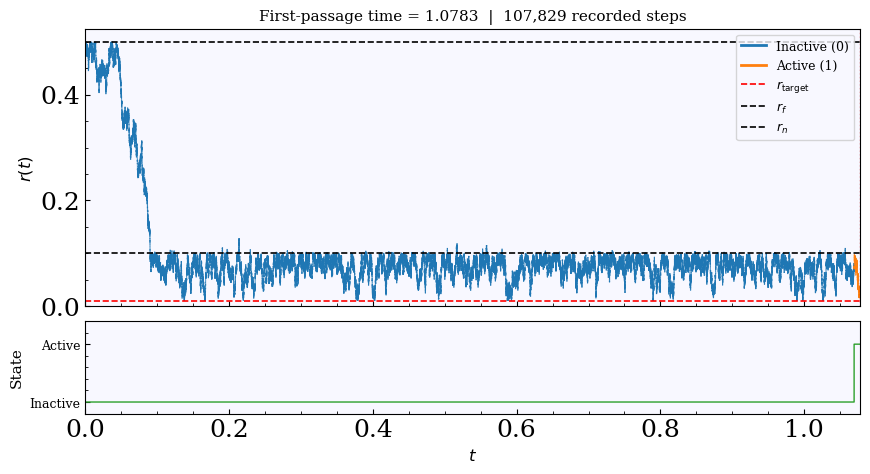

In [32]:
# ──────────────────────────────────────────────────────────────────────────────
# Internal helpers  (identical to the original)
# ──────────────────────────────────────────────────────────────────────────────

@njit(cache=True)
def _exp_term(r, b, rf):
    return np.exp(-b * (r - rf))

@njit(cache=True)
def _D_func(r, b, rf, D0, Dn):
    e = _exp_term(r, b, rf)
    return D0 + (Dn - D0) / (1.0 + e)

@njit(cache=True)
def _dD_func(r, b, rf, D0, Dn):
    e = _exp_term(r, b, rf)
    return (Dn - D0) * b * e / (1.0 + e) ** 2

@njit(cache=True)
def _dU_func(r, b, rf, A):
    e = _exp_term(r, b, rf)
    return A * b * e / (1.0 + e) ** 2

@njit(cache=True)
def _mu_func(r, b, rf, A, D0, Dn, ndim):
    D  = _D_func(r, b, rf, D0, Dn)
    dD = _dD_func(r, b, rf, D0, Dn)
    dU = _dU_func(r, b, rf, A)
    return (ndim - 1) * D / r + dD - D * dU

@njit(cache=True)
def _lambda_func(r, b, rf, lambda0):
    #e = _exp_term(r, b, rf)
    return lambda0 #* e / (1.0 + e)

@njit(cache=True)
def _draw_switch_time(state, r, gamma, b, rf, lambda0):
    if state == 1: 
        # In the active state, the switching rate is constant (gamma), so we can sample directly from Exp(gamma).
        if gamma == 0.0:
            return np.inf
        return np.random.exponential(1.0 / gamma)
    else:
        # In the inactive state, the switching rate depends on position, so we sample from an inhomogeneous Poisson process.
        if lambda0 == 0.0:
            return np.inf
        for _ in range(10_000):          # ← safety cap
            t_proposal =  np.random.exponential(1.0 / lambda0)
            lam_r = _lambda_func(r, b, rf, lambda0)
            if np.random.random() < lam_r / lambda0:
                return t_proposal
        #print("Warning: Failed to draw switch time after many attempts.")
        return np.inf                    # give up, treat as no switch


# ──────────────────────────────────────────────────────────────────────────────
# Single-trajectory recorder
# ──────────────────────────────────────────────────────────────────────────────

@njit(cache=True)
def _run_single_trajectory(
    r0, state0, r_target, rf, rn,
    A, b, D0, Dn, lambda0, gamma,
    ndim, dt, max_steps,
):
    """
    Simulate one particle and record (t, r, state) at every time step.

    Returns
    -------
    times  : float64 array  – time at each recorded step
    rs     : float64 array  – radial position at each step
    states : int32   array  – activity state (0 = inactive, 1 = active)
    absorbed : bool         – True if the particle reached r_target
    fpt    : float          – first-passage time (NaN if not absorbed)
    """
    sqrt_dt = np.sqrt(dt)

    # Pre-allocate storage.  We'll trim at the end.
    times  = np.empty(max_steps + 2, dtype=np.float64)
    rs     = np.empty(max_steps + 2, dtype=np.float64)
    states = np.empty(max_steps + 2, dtype=np.int32)

    r     = r0
    state = state0
    t     = 0.0

    # Record initial condition
    times[0]  = t
    rs[0]     = r
    states[0] = state

    n_recorded = 1

    t_switch = t + _draw_switch_time(state, r, gamma, b, rf, lambda0)

    absorbed = False
    fpt      = np.nan

    for _ in range(max_steps):
        D  = _D_func(r, b, rf, D0, Dn)
        mu = _mu_func(r, b, rf, A, D0, Dn, ndim)

        # Euler–Maruyama step
        r_new = r + mu * dt + np.sqrt(2.0 * D) * sqrt_dt * np.random.standard_normal()

        # Reflect at outer boundary
        if r_new > rn:
            r_new = 2.0 * rn - r_new

        t += dt

        if r_new <= r_target:
            if state == 1:
                # Linear interpolation for exact crossing time
                frac = (r - r_target) / (r - r_new)
                fpt  = (t - dt) + frac * dt
                # Append the absorption point and stop
                times[n_recorded]  = fpt
                rs[n_recorded]     = r_target
                states[n_recorded] = state
                n_recorded += 1
                absorbed = True
                break
            else:
                # Reflect inactive particle off the target
                r_new = 2.0 * r_target - r_new

        # State switch
        if t >= t_switch:
            state    = 1 - state
            t_switch = t + _draw_switch_time(state, r_new, gamma, b, rf, lambda0)

        r = r_new

        # Record step
        times[n_recorded]  = t
        rs[n_recorded]     = r
        states[n_recorded] = state
        n_recorded        += 1

    return (
        times[:n_recorded],
        rs[:n_recorded],
        states[:n_recorded],
        absorbed,
        fpt,
    )


# ──────────────────────────────────────────────────────────────────────────────
# Public API
# ──────────────────────────────────────────────────────────────────────────────

def simulate_trajectory(
    r0: float,
    state0: int,
    r_target: float,
    rf: float,
    rn: float,
    A: float,
    b: float,
    D0: float,
    Dn: float,
    lambda0: float = 0.01,
    gamma: float   = 0.01,
    ndim: int      = 3,
    dt: float      = 1e-2,
    max_steps: int = 10_000_000,
    seed: int | None = None,
) -> dict:
    """
    Simulate a single two-state particle trajectory and return the full path.

    Parameters
    ----------
    r0        : initial radial position
    state0    : initial activity state (0 = inactive, 1 = active)
    r_target  : absorbing target radius
    rf        : sigmoid midpoint radius (for D, lambda, U profiles)
    rn        : reflecting outer boundary
    A         : potential amplitude
    b         : sigmoid steepness
    D0        : diffusivity at r >> rf
    Dn        : diffusivity at r << rf
    lambda0   : max inactivation rate (state 1 → 0)
    gamma     : activation rate       (state 0 → 1)
    ndim      : spatial dimension (default 3)
    dt        : time step
    max_steps : safety cap on simulation length
    seed      : random seed (None for non-reproducible)

    Returns
    -------
    dict with keys
      "times"    : 1-D float array  – time points
      "rs"       : 1-D float array  – radial positions r(t)
      "states"   : 1-D int array    – activity states (0 or 1)
      "absorbed" : bool             – whether the particle was absorbed
      "fpt"      : float            – first-passage time (NaN if not absorbed)
    """
    if seed is not None:
        np.random.seed(seed)

    times, rs, states, absorbed, fpt = _run_single_trajectory(
        r0, state0, r_target, rf, rn,
        A, b, D0, Dn, lambda0, gamma,
        ndim, dt, max_steps,
    )

    return {
        "times"   : times,
        "rs"      : rs,
        "states"  : states,
        "absorbed": absorbed,
        "fpt"     : fpt,
    }


# ──────────────────────────────────────────────────────────────────────────────
# Quick visualisation helper  (optional, requires matplotlib)
# ──────────────────────────────────────────────────────────────────────────────

def plot_trajectory(result: dict, r_target: float, rn: float) -> None:
    """
    Plot r(t) coloured by activity state and the state signal below.

    Parameters
    ----------
    result   : dict returned by simulate_trajectory()
    r_target : absorbing boundary (drawn as a dashed line)
    rn       : outer boundary (drawn as a dashed line)
    """
    import matplotlib.pyplot as plt
    import matplotlib.collections as mc

    t      = result["times"]
    r      = result["rs"]
    states = result["states"]

    # Build coloured line segments for r(t)
    points  = np.column_stack([t, r])
    segs    = np.stack([points[:-1], points[1:]], axis=1)
    colours = np.where(states[:-1] == 1, "tab:orange", "tab:blue")

    lc = mc.LineCollection(segs, colors=colours, linewidths=0.8, alpha=0.85)

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(10, 5), sharex=True,
        gridspec_kw={"height_ratios": [3, 1], "hspace": 0.08},
    )

    # ── top panel: trajectory ──────────────────────────────────────────────
    ax1.add_collection(lc)
    ax1.axhline(r_target, color="red",   ls="--", lw=1.2, label=r"$r_{\rm target}$")
    ax1.axhline(rf,       color="black", ls="--", lw=1.2, label=r"$r_f$")
    ax1.axhline(rn,       color="black", ls="--", lw=1.2, label=r"$r_n$")
    ax1.set_xlim(t[0], t[-1])
    ax1.set_ylim(0, rn * 1.05)
    ax1.set_ylabel(r"$r(t)$", fontsize=12)
    ax1.legend(loc="upper right", fontsize=9)

    if result["absorbed"]:
        ax1.axvline(result["fpt"], color="red", lw=1, ls=":", alpha=0.7)
        ax1.set_title(
            f"First-passage time = {result['fpt']:.4f}  |  "
            f"{len(t):,} recorded steps",
            fontsize=11,
        )
    else:
        ax1.set_title(f"Trajectory truncated after {len(t):,} steps (no absorption)", fontsize=11)

    # Dummy handles for the state colours
    from matplotlib.lines import Line2D
    ax1.legend(
        handles=[
            Line2D([0], [0], color="tab:blue",   lw=2, label="Inactive (0)"),
            Line2D([0], [0], color="tab:orange", lw=2, label="Active (1)"),
            Line2D([0], [0], color="red",   ls="--", lw=1.2, label=r"$r_{\rm target}$"),
            Line2D([0], [0], color="black", ls="--", lw=1.2, label=r"$r_f$"),
            Line2D([0], [0], color="black", ls="--", lw=1.2, label=r"$r_n$"),
        ],
        loc="upper right", fontsize=9,
    )

    # ── bottom panel: state signal ─────────────────────────────────────────
    ax2.step(t, states, where="post", color="tab:green", lw=1.0)
    ax2.set_yticks([0, 1])
    ax2.set_yticklabels(["Inactive", "Active"], fontsize=9)
    ax2.set_xlabel(r"$t$", fontsize=12)
    ax2.set_ylabel("State", fontsize=11)
    ax2.set_ylim(-0.2, 1.4)

    plt.tight_layout()
    plt.show()


# ──────────────────────────────────────────────────────────────────────────────
# Example usage
# ──────────────────────────────────────────────────────────────────────────────

if __name__ == "__main__":

    r_target = 0.01
    rf = 0.1
    rn = 0.5
    A = 5.0
    b = 500.0
    D = 0.2
    lambda0 = 5.0
    gamma = 5.0

    result = simulate_trajectory(
        r0       = rn,
        state0   = 0,
        r_target = r_target,
        rf       = 0.1,
        rn       = rn,
        A        = A,
        b        = b,
        D0       = D,
        Dn       = D,
        lambda0  = lambda0,
        gamma    = gamma,
        ndim     = 3,
        dt       = 1e-5,
        seed     = 42,
    )

    print(f"Absorbed : {result['absorbed']}")
    print(f"FPT      : {result['fpt']:.4f}")
    print(f"Steps    : {len(result['times']):,}")

    plot_trajectory(result, r_target=r_target, rn=rn)